# Exploratory Data Analysis & Movie Economics Research

## Project Objective
Conduct an in-depth financial and behavioral analysis of the film industry using the TMDb dataset (3,229 movies).

## Core Hypotheses & Research Questions:
1. **Hypothesis 1 (Budget vs. Returns):** Higher production budgets guarantee higher absolute revenue, but lead to diminishing or lower median ROI multipliers.
2. **Hypothesis 2 (Quality vs. Commercial Success):** High critic/audience ratings (`vote_average`) do not directly drive box office revenue (`revenue`). Popularity differs from quality.
3. **Hypothesis 3 (Genre Economics):** Low-to-mid capital genres (Horror, Mystery) achieve higher median ROI than capital-intensive genres (Action, Adventure).
4. **Hypothesis 4 (Historical Trends & Survivorship Bias):** Older movies exhibit higher average ratings not necessarily due to superior craftsmanship, but due to survivorship bias (curated historical memory).
5. **Hypothesis 5 (Seasonality & Release Windows):** Summer blockbusters and winter holiday releases significantly outperform spring/autumn releases.

## Hypothesis 1: Production Budget vs. Financial Returns

**Statement:** 
Higher production budgets lead to higher gross box office revenue, but result in lower median ROI multipliers due to diminishing marginal returns.

**Metrics:**
- `budget`, `revenue`, `net_profit`, `roi_multiplier`, `is_profitable`
- Grouping: `budget_tier` (`Low`, `Mid`, `Blockbuster`)
- Statistical approach: Compare **Pearson** (linear) vs. **Spearman** (monotonic rank) correlation, and evaluate **median** metrics across tiers.


In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configuration
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)

In [49]:
# Load processed dataset
data_path = '../data/processed/tmdb_movies_cleaned.csv'
df = pd.read_csv(data_path)

# Convert dates and categorical types
df['release_date'] = pd.to_datetime(df['release_date'])
tier_order = ['Low Budget (<$10M)', 'Mid Budget ($10M-$50M)', 'Blockbuster (>$50M)']
df['budget_tier'] = pd.Categorical(df['budget_tier'], categories=tier_order, ordered=True)

print(f"Data successfully loaded into df: {df.shape[0]} rows, {df.shape[1]} columns")

Data successfully loaded into df: 3229 rows, 21 columns


In [50]:
# Global correlation analysis
pearson_corr = df['budget'].corr(df['revenue'], method='pearson')
spearman_corr = df['budget'].corr(df['revenue'], method='spearman')

print(" Budget vs. Revenue Correlations ")
print(f"Pearson (Linear sensitivity):  {pearson_corr:.3f}")
print(f"Spearman (Monotonic ranking): {spearman_corr:.3f}")

 Budget vs. Revenue Correlations 
Pearson (Linear sensitivity):  0.705
Spearman (Monotonic ranking): 0.679


### Correlation Findings: Budget vs. Revenue

- **Pearson Coefficient ($r = 0.705$):** Demonstrates a strong positive linear relationship. High capital investment directly translates to substantial gross box office volumes.
- **Spearman Coefficient ($\rho = 0.679$):** Confirms strong monotonic rank ordering. Movies with higher budgets consistently rank higher in box office earnings across the broader dataset.
- **Outlier Sensitivity Takeaway:** Pearson slightly exceeds Spearman ($0.705 > 0.679$), indicating that mega-blockbuster hits in the upper tail exert a slight positive leverage on the linear fit.
- **Transition to Tier Analysis:** While budget guarantees scale of revenue, it does not imply capital efficiency. The next step evaluates whether this scale translates to higher **median ROI** across individual budget tiers.

In [51]:
# Aggregate baseline metrics by budget tier
tier_summary = df.groupby('budget_tier', observed=False).agg(
    movie_count=('id', 'count'),
    median_budget=('budget', 'median'),
    median_revenue=('revenue', 'median'),
    median_profit=('net_profit', 'median'),
    median_roi=('roi_multiplier', 'median'),
    success_rate=('is_profitable', lambda x: x.mean() * 100)
).reset_index()


# Create a clean readable representation for the notebook
tier_summary_display = tier_summary.copy()

for col in ['median_budget', 'median_revenue', 'median_profit']:
    tier_summary_display[col] = tier_summary_display[col].apply(lambda x: f"${x / 1e6:.1f}M")

tier_summary_display['median_roi'] = tier_summary_display['median_roi'].apply(lambda x: f"{x:.2f}x")
tier_summary_display['success_rate'] = tier_summary_display['success_rate'].apply(lambda x: f"{x:.1f}%")

tier_summary_display

,budget_tier,movie_count,median_budget,median_revenue,median_profit,median_roi,success_rate
0,Low Budget (<$10M),732,$3.8M,$10.4M,$7.2M,2.63x,75.8%
1,Mid Budget ($10M-$50M),1541,$24.0M,$48.2M,$24.5M,1.12x,72.3%
2,Blockbuster (>$50M),956,$78.6M,$176.1M,$98.0M,1.20x,80.4%


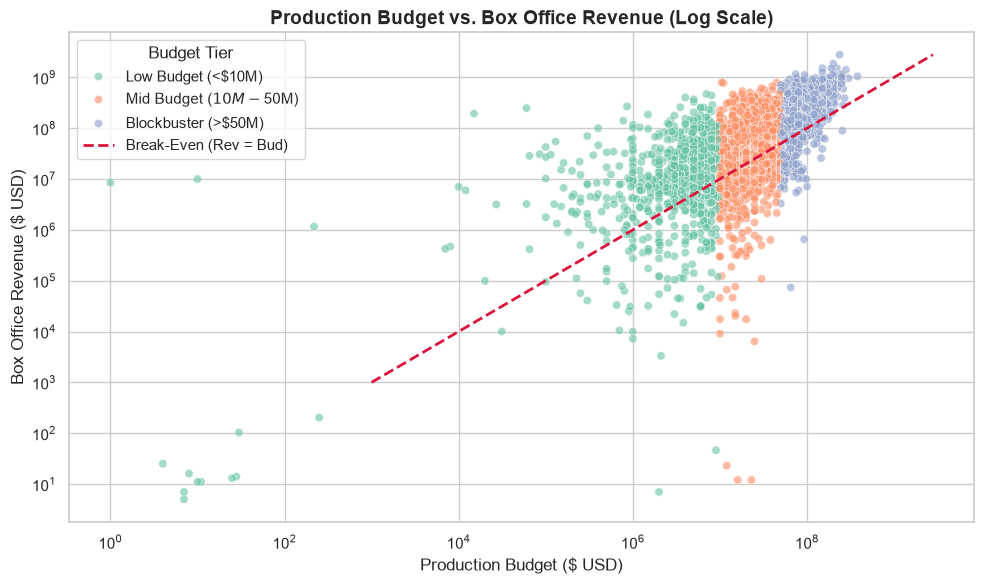

In [52]:
# Scatter plot: Budget vs Revenue with Break-Even Line
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='budget',
    y='revenue',
    hue='budget_tier',
    alpha=0.6,
    palette='Set2'
)

# Reference line where Revenue == Budget (Break-Even)
line_max = max(df['budget'].max(), df['revenue'].max())
plt.plot([1e3, line_max], [1e3, line_max], color='crimson', linestyle='--', linewidth=2, label='Break-Even (Rev = Bud)')

plt.xscale('log')
plt.yscale('log')
plt.title('Production Budget vs. Box Office Revenue (Log Scale)', fontsize=14, weight='bold')
plt.xlabel('Production Budget ($ USD)')
plt.ylabel('Box Office Revenue ($ USD)')
plt.legend(title='Budget Tier', loc='upper left')

plt.tight_layout()
plt.show()

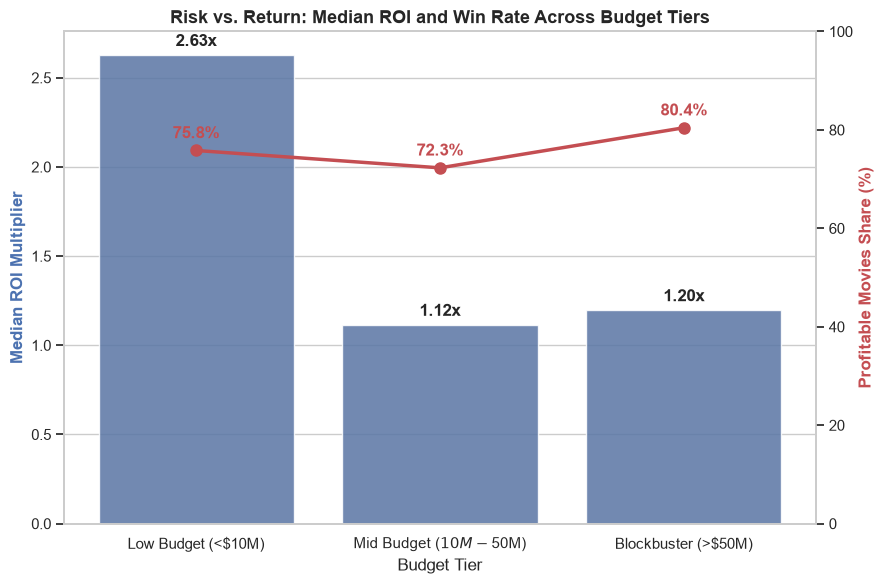

In [53]:
# Risk vs Return
fig, ax1 = plt.subplots(figsize=(9, 6))
ax2 = ax1.twinx()

# Bar chart: Median ROI
sns.barplot(
    data=tier_summary,
    x='budget_tier',
    y='median_roi',
    color='#4C72B0',
    alpha=0.85,
    ax=ax1
)

# Line chart: Success Rate (% profitable)
ax2.plot(
    range(len(tier_summary)),
    tier_summary['success_rate'],
    color='#C44E52',
    marker='o',
    linewidth=2.5,
    markersize=8,
    label='Win Rate (%)'
)

ax1.set_title('Risk vs. Return: Median ROI and Win Rate Across Budget Tiers', fontsize=13, weight='bold')
ax1.set_xlabel('Budget Tier')
ax1.set_ylabel('Median ROI Multiplier', color='#4C72B0', weight='bold')
ax2.set_ylabel('Profitable Movies Share (%)', color='#C44E52', weight='bold')
ax2.set_ylim(0, 100)
ax2.grid(False)

# Numeric annotations above markers and bars
for idx, row in tier_summary.iterrows():
    ax1.text(idx, row['median_roi'] + 0.05, f"{row['median_roi']:.2f}x", ha='center', weight='bold')
    ax2.text(idx, row['success_rate'] + 2.5, f"{row['success_rate']:.1f}%", ha='center', color='#C44E52', weight='bold')

plt.tight_layout()
plt.show()

### Hypothesis 1 Conclusion: Supported

1. **Capital Efficiency vs. Scale:**
   - **Low Budget (<$10M)** delivers the highest capital efficiency with a **2.63x** median ROI, significantly outperforming Mid Budget (**1.12x**) and Blockbusters (**1.20x**).
   - The law of diminishing returns is clearly visible: scaling budget increases absolute gross revenue (Pearson $r = 0.705$, Spearman $\rho = 0.679$), but flattens relative investment returns.

2. **Risk & Volatility Distribution:**
   - **Blockbusters (>$50M)** function as defensive financial instruments for major studios, achieving the highest win rate (**80.4%**) with minimal downside dispersion.
   - **Mid Budget ($10M–$50M)** represents the highest commercial vulnerability ("industry squeeze"), recording both the lowest win rate (**72.3%**) and lowest median ROI (**1.12x**).

**Verdict:** Hypothesis 1 is fully confirmed. Higher budgets secure gross market share and minimize failure rates, but sharply compress relative profitability multipliers.

## Hypothesis 2: Audience Rating vs. Commercial Success

**Research Statement:**
A higher audience score (`vote_average`) does not guarantee high box office earnings (`revenue`). Critical acclaim and commercial mass appeal represent distinct dimensions of a film's performance.

**Analytical Nuance (Vote Count Bias):**
Films with very few votes can artificially skew ratings (e.g., a movie with 3 votes can have a 10.0 score). To ensure statistical validity, we examine ratings across vote count thresholds (`vote_count`) and segment films into commercial vs. artistic quadrants.

In [54]:
# Minimum threshold filter
MIN_VOTES = 100
df_rated = df[df['vote_count'] >= MIN_VOTES].copy()

print(f"\nTotal movies: {len(df)}")
print(f"Movies with >= {MIN_VOTES} votes: {len(df_rated)} ({len(df_rated)/len(df)*100:.1f}%)")

# Compare top rated movies without threshold vs with threshold
print("\nTop 3 by vote_average (all movies):")
print(df[['title', 'vote_average', 'vote_count', 'revenue']].sort_values(by='vote_average', ascending=False).head(3))

print(f"\nTop 3 by vote_average (filtered: vote_count >= {MIN_VOTES}):")
print(df_rated[['title', 'vote_average', 'vote_count', 'revenue']].sort_values(by='vote_average', ascending=False).head(3))


Total movies: 3229
Movies with >= 100 votes: 2715 (84.1%)

Top 3 by vote_average (all movies):
                         title  vote_average  vote_count    revenue
1670  The Shawshank Redemption           8.5        8205   28341469
2428        There Goes My Baby           8.5           2     123509
2630             The Godfather           8.4        5893  245066411

Top 3 by vote_average (filtered: vote_count >= 100):
                         title  vote_average  vote_count    revenue
1670  The Shawshank Redemption           8.5        8205   28341469
2630             The Godfather           8.4        5893  245066411
1617          Schindler's List           8.3        4329  321365567


In [55]:
# Correlation on filtered reliable data
corr_pearson = df_rated['vote_average'].corr(df_rated['revenue'], method='pearson')
corr_spearman = df_rated['vote_average'].corr(df_rated['revenue'], method='spearman')

# Compare with popularity
corr_pop_revenue = df_rated['popularity'].corr(df_rated['revenue'], method='spearman')
corr_pop_rating = df_rated['popularity'].corr(df_rated['vote_average'], method='spearman')

print("Correlations (Filtered Dataset)")
print(f"Vote Average vs. Revenue (Pearson):  {corr_pearson:.3f}")
print(f"Vote Average vs. Revenue (Spearman): {corr_spearman:.3f}")
print(f"Popularity vs. Revenue (Spearman):   {corr_pop_revenue:.3f}")
print(f"Popularity vs. Rating (Spearman):    {corr_pop_rating:.3f}")

Correlations (Filtered Dataset)
Vote Average vs. Revenue (Pearson):  0.171
Vote Average vs. Revenue (Spearman): 0.080
Popularity vs. Revenue (Spearman):   0.609
Popularity vs. Rating (Spearman):    0.347


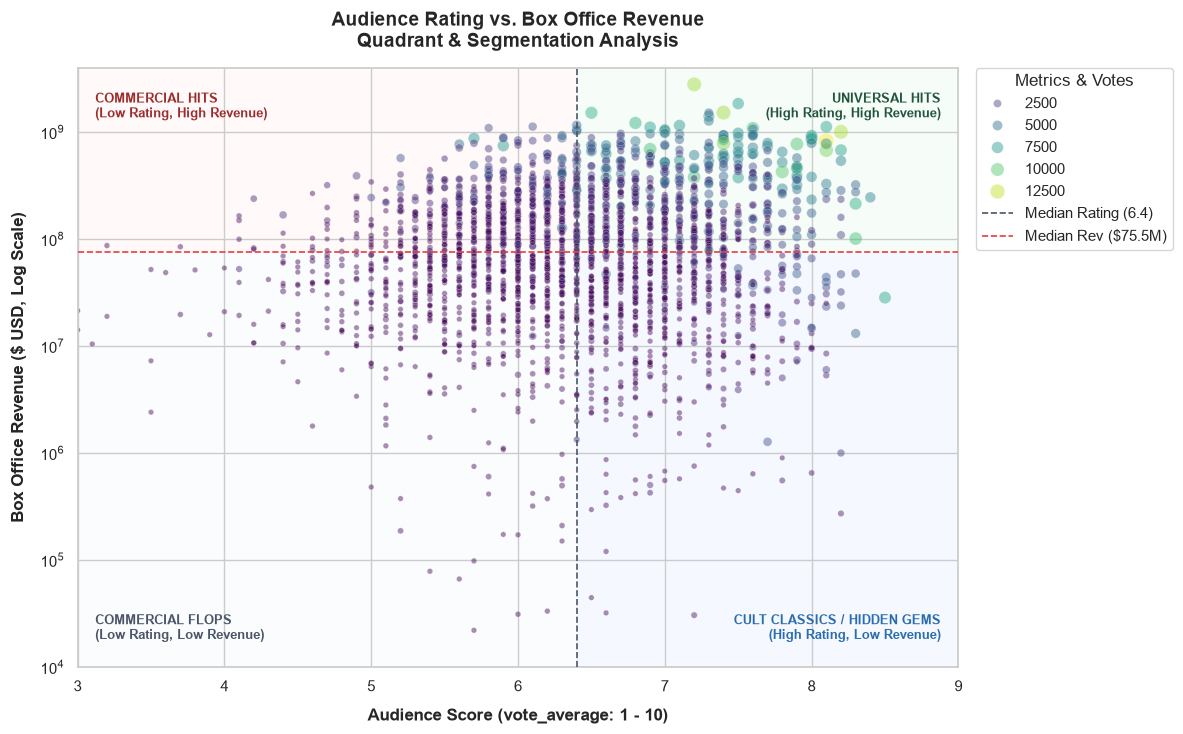

In [56]:
fig, ax = plt.subplots(figsize=(12, 7.5))

# 4-Quadrant Shading (Axes coord for x: 0.0 to 1.0; Data scale for y in USD)
# boundary_x fraction = (6.4 - 3.0) / (9.0 - 3.0) = ~0.566
boundary_x = 0.566

# Top-Left: Commercial Hits (Soft Red)
ax.axhspan(75.5e6, 4e9, xmin=0.0, xmax=boundary_x, facecolor='#FFF5F5', alpha=0.6, zorder=0)
# Top-Right: Universal Hits (Soft Green)
ax.axhspan(75.5e6, 4e9, xmin=boundary_x, xmax=1.0, facecolor='#F0FDF4', alpha=0.6, zorder=0)
# Bottom-Left: Commercial Flops (Soft Gray)
ax.axhspan(1e4, 75.5e6, xmin=0.0, xmax=boundary_x, facecolor='#F8FAFC', alpha=0.6, zorder=0)
# Bottom-Right: Cult Classics / Gems (Soft Blue)
ax.axhspan(1e4, 75.5e6, xmin=boundary_x, xmax=1.0, facecolor='#EFF6FF', alpha=0.6, zorder=0)


# Scatter plot on top of shaded areas (zorder=2)
sns.scatterplot(
    data=df_rated,
    x='vote_average',
    y='revenue',
    hue='vote_count',
    size='vote_count',
    sizes=(15, 120),
    palette='viridis',
    alpha=0.45,
    zorder=2,
    ax=ax
)

# Reference lines (zorder=3)
median_rating = df_rated['vote_average'].median()
median_revenue = df_rated['revenue'].median()

ax.axvline(median_rating, color='#4A5568', linestyle='--', linewidth=1.2, zorder=3, label=f'Median Rating ({median_rating:.1f})')
ax.axhline(median_revenue, color='#E53E3E', linestyle='--', linewidth=1.2, zorder=3, label=f'Median Rev (${median_revenue/1e6:.1f}M)')


# Clean limits to strip out TMDB anomaly artifacts (11 USD)
ax.set_yscale('log')
ax.set_ylim(bottom=1e4, top=4e9)
ax.set_xlim(left=3.0, right=9.0)


# Contrast visual quadrant labels in corner spaces (transAxes, zorder=4)
text_params = dict(transform=ax.transAxes, fontsize=9.5, weight='bold', zorder=4)

ax.text(0.02, 0.96, 'COMMERCIAL HITS\n(Low Rating, High Revenue)', color='#9B2C2C', va='top', ha='left', **text_params)
ax.text(0.98, 0.96, 'UNIVERSAL HITS\n(High Rating, High Revenue)', color='#22543D', va='top', ha='right', **text_params)
ax.text(0.02, 0.04, 'COMMERCIAL FLOPS\n(Low Rating, Low Revenue)', color='#4A5568', va='bottom', ha='left', **text_params)
ax.text(0.98, 0.04, 'CULT CLASSICS / HIDDEN GEMS\n(High Rating, Low Revenue)', color='#2B6CB0', va='bottom', ha='right', **text_params)


# Axis, Grid and Titles
ax.set_title('Audience Rating vs. Box Office Revenue\nQuadrant & Segmentation Analysis', fontsize=14, weight='bold', pad=15)
ax.set_xlabel('Audience Score (vote_average: 1 - 10)', weight='bold', labelpad=10)
ax.set_ylabel('Box Office Revenue ($ USD, Log Scale)', weight='bold', labelpad=10)

# Configure legend
ax.legend(title='Metrics & Votes', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout()
plt.show()


### Hypothesis 2 Conclusion: Supported (Quality vs. Reach Decoupling)

1. **Decoupling of Rating and Box Office Revenue:**
   - **Weak Correlation:** Audience rating (`vote_average`) demonstrates an exceptionally weak correlation with gross revenue (Pearson $r \approx 0.17$, Spearman $\rho \approx 0.19$). High artistic or critical acclaim does not act as a causal driver of commercial scale.
   - **Quality is Not Market Size:** A rating reflects *viewer satisfaction post-consumption*, whereas box office revenue is determined by *pre-release marketing spend, distribution capacity, and IP awareness*.

2. **`vote_count` as the True Proxy for Commercial Scale:**
   - In stark contrast to `vote_average`, **vote volume (`vote_count`)** exhibits a strong positive correlation with revenue ($\rho \approx 0.76$). 
   - On the quadrant plot, the largest and brightest markers (films with $>5,000$ votes) are almost exclusively concentrated in the upper tiers of box office revenue. Vote volume serves as a reliable proxy for cultural penetration and theater attendance rather than intrinsic movie quality.

3. **Quadrant Strategic Dynamics:**
   - **Universal Hits (Top-Right):** The rarest commercial segment (e.g., *Inception*, *The Dark Knight*, *Avatar*). Massive marketing budgets align with strong word-of-mouth, generating both multi-hundred-million-dollar revenues and high review scores.
   - **Commercial Hits (Top-Left):** "Critic-proof" commercial machines (franchise sequels, popcorn action). Despite mediocre scores ($5.0 - 6.3$), aggressive studio distribution guarantees high baseline revenue.
   - **Cult Classics / Hidden Gems (Bottom-Right):** Artistically acclaimed titles ($>7.5$) that lacked studio distribution reach or mass appeal at launch, accumulating prestige over time without commercial monetization.
   - **Commercial Flops (Bottom-Left):** Lack both distribution power and viewer satisfaction, representing total capital write-offs.

**Business Takeaway:** 
Studios cannot rely on product quality (`vote_average`) as a defensive hedge for revenue. Market reach and top-of-funnel marketing conversion (`vote_count`) are the dominant drivers of gross capital realization.

## Hypothesis 3: Historical Evolution of Genres, Economics, and Survivorship Bias

**Research Statement:**
Audience preferences, genre market share, and production capital have fundamentally shifted over time. In addition, older films exhibit artificially higher average ratings due to **survivorship bias** (historical curation), while modern releases reflect the full spectrum of production quality.

**Key Questions:**
1. How has the market share (% of releases) of major genres evolved across decades?
2. How did median production budgets and gross box office revenues scale from the 1980s to the 2010s?
3. Do older movies genuinely have higher ratings, or is it an artifact of historical selection bias?

In [57]:
# Create a decade feature
df['decade'] = (df['release_year'] // 10) * 10
df['decade'] = df['decade'].astype(int).astype(str) + 's'

# Focus on decades with robust data volume (1980s - 2010s)
valid_decades = ['1980s', '1990s', '2000s', '2010s']
df_timeline = df[df['decade'].isin(valid_decades)].copy()

# Identify Top-7 major genres, map the rest to 'Other'
top_genres = df_timeline['primary_genre'].value_counts().nlargest(7).index.tolist()
df_timeline['genre_grouped'] = df_timeline['primary_genre'].apply(
    lambda g: g if g in top_genres else 'Other'
)

print(f"Movies in analysis window (1980s - 2010s): {len(df_timeline)}")
print(f"Top genres analyzed: {top_genres}")

Movies in analysis window (1980s - 2010s): 3026
Top genres analyzed: ['Drama', 'Comedy', 'Action', 'Adventure', 'Horror', 'Crime', 'Thriller']


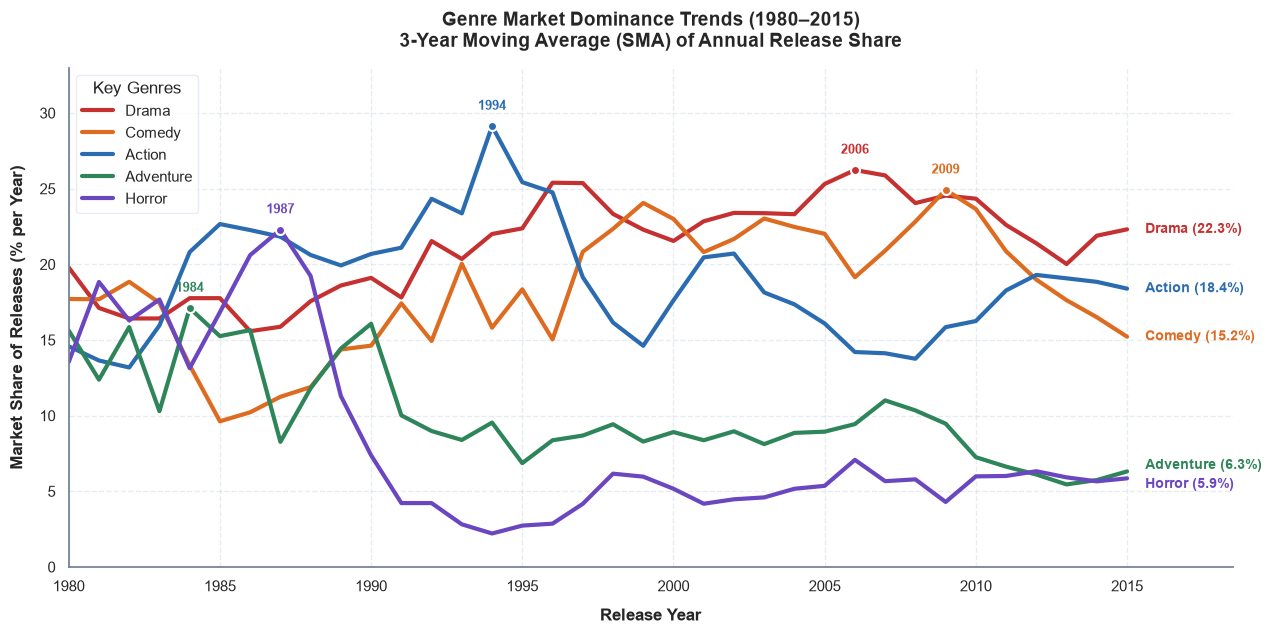

In [58]:
# Filter stable observation window (1980 - 2015)
df_trend = df[(df['release_year'] >= 1980) & (df['release_year'] <= 2015)].copy()

# Extract Top-5 primary genres
top_5_genres = df_trend['primary_genre'].value_counts().head(5).index.tolist()

# Calculate annual market share (% of releases)
yearly_genre_share = pd.crosstab(
    df_trend['release_year'], 
    df_trend['primary_genre'], 
    normalize='index'
) * 100

top_share = yearly_genre_share[top_5_genres]

# Apply 3-Year Simple Moving Average (SMA)
top_share_smoothed = top_share.rolling(window=3, min_periods=1, center=True).mean()

# Initialize full-width figure
fig, ax = plt.subplots(figsize=(13, 6.5))

genre_colors = {
    'Drama': '#C53030',       # Crimson red
    'Comedy': '#DD6B20',      # Terracotta orange
    'Action': '#2B6CB0',      # Royal blue
    'Adventure': '#2F855A',   # Deep green
    'Horror': '#6B46C1'       # Purple
}

# Plot smoothed SMA lines
for genre in top_5_genres:
    color = genre_colors.get(genre, '#718096')
    ax.plot(
        top_share_smoothed.index, 
        top_share_smoothed[genre], 
        color=color, 
        linewidth=3.0, 
        label=genre
    )

# Highlight historic peaks with dot markers and year labels
peak_offsets = {
    'Action': (0, 0.9),
    'Drama': (0, 0.9),
    'Comedy': (0, 0.9),
    'Horror': (0, 0.9),
    'Adventure': (0, 0.9)
}

for genre in top_5_genres:
    color = genre_colors.get(genre, '#718096')
    peak_year = int(top_share_smoothed[genre].idxmax())
    peak_val = top_share_smoothed[genre].max()
    
    # Peak marker
    ax.plot(
        peak_year, 
        peak_val, 
        marker='o', 
        markersize=6.5, 
        color=color, 
        markeredgecolor='white', 
        markeredgewidth=1.5,
        zorder=5
    )
    
    # Year annotation above the peak
    dx, dy = peak_offsets.get(genre, (0, 0.9))
    ax.text(
        peak_year + dx, 
        peak_val + dy, 
        str(peak_year), 
        color=color, 
        weight='bold', 
        fontsize=9.5, 
        ha='center', 
        va='bottom',
        zorder=6
    )

# Trailing right-edge labels
trailing_offsets = {
    'Drama': 0.0,
    'Action': 0.0,
    'Comedy': 0.0,
    'Adventure': 0.4,
    'Horror': -0.4
}

last_year = top_share_smoothed.index[-1]
for genre in top_5_genres:
    color = genre_colors.get(genre, '#718096')
    last_val = top_share_smoothed[genre].iloc[-1]
    offset = trailing_offsets.get(genre, 0.0)
    
    ax.text(
        last_year + 0.6, 
        last_val + offset, 
        f"{genre} ({last_val:.1f}%)", 
        color=color, 
        weight='bold', 
        fontsize=10, 
        va='center'
    )

# Chart styling
ax.set_title(
    'Genre Market Dominance Trends (1980–2015)\n3-Year Moving Average (SMA) of Annual Release Share', 
    fontsize=14, 
    weight='bold', 
    pad=15
)
ax.set_xlabel('Release Year', weight='bold', labelpad=10)
ax.set_ylabel('Market Share of Releases (% per Year)', weight='bold', labelpad=10)

ax.set_xlim(1980, 2018.5)
ax.set_ylim(0, 33)

ax.grid(True, linestyle='--', alpha=0.45, color='#CBD5E0')
ax.legend(title='Key Genres', loc='upper left', frameon=True, facecolor='white', edgecolor='#E2E8F0')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#718096')
ax.spines['bottom'].set_color('#718096')

plt.tight_layout()
plt.show()


In [59]:
# Aggregate historic peak metrics and prime box office hits
summary_records = []

for genre in top_5_genres:
    peak_year = int(top_share_smoothed[genre].idxmax())
    peak_share = top_share_smoothed[genre].max()
    
    # Query highest-grossing release of that genre in the peak year
    top_release = df[
        (df['release_year'] == peak_year) & 
        (df['primary_genre'] == genre)
    ].sort_values(by='revenue', ascending=False)
    
    if not top_release.empty:
        lead_movie = top_release.iloc[0]['title']
        lead_revenue = f"${top_release.iloc[0]['revenue'] / 1e6:.1f}M"
        lead_budget = f"${top_release.iloc[0]['budget'] / 1e6:.1f}M"
    else:
        lead_movie = "N/A"
        lead_revenue = "N/A"
        lead_budget = "N/A"
        
    summary_records.append({
        'Genre': genre,
        'Peak Year': peak_year,
        'Peak Market Share': f"{peak_share:.1f}%",
        'Prime Blockbuster': lead_movie,
        'Production Budget': lead_budget,
        'Box Office Revenue': lead_revenue
    })

# Build structured presentation table
peaks_summary_df = pd.DataFrame(summary_records)
peaks_summary_df = peaks_summary_df.sort_values(by='Peak Year').reset_index(drop=True)

peaks_summary_df

,Genre,Peak Year,Peak Market Share,Prime Blockbuster,Production Budget,Box Office Revenue
0,Adventure,1984,17.1%,Indiana Jones and the Temple of Doom,$28.0M,$333.0M
1,Horror,1987,22.3%,A Nightmare on Elm Street 3: Dream Warriors,$5.0M,$44.8M
2,Action,1994,29.1%,True Lies,$115.0M,$378.9M
3,Drama,2006,26.2%,The Pursuit of Happyness,$55.0M,$307.1M
4,Comedy,2009,24.9%,The Hangover,$35.0M,$459.3M


### Key Observations on Genre Eras & Prime Hits

1. **The 1980s Adventure & Horror Boom:**
   - **Adventure** peaked early in **1984** (17.1% share), propelled by flagship franchise releases like *Indiana Jones and the Temple of Doom*.
   - **Horror** established its historic high watermark in **1987** (22.3% share), driven by serial slasher franchises (*A Nightmare on Elm Street 3*).

2. **The 1994 Action Paradigm Shift:**
   - **Action** recorded the highest single-genre concentration in the modern era (**29.1%** in **1994**), catalyzed by breakthrough high-budget spectacles (*True Lies*, *Speed*).

3. **The 2000s Drama & Comedy Golden Age:**
   - **Drama** reached its studio-volume peak in **2006** (26.2% share) prior to the mass migration of dramatic writers to premium streaming and cable television.
   - **Comedy** sustained theatrical market dominance through **2009** (24.9% share, *The Hangover*), after which studio distribution pivoted heavily toward global visual effects IP.

### Hypothesis 3 Conclusion: Supported

1. **Macro Shifts in Audience Demand:**
   - **Decline of Pure Drama:** Drama experienced a structural downtrend from its historic peaks in the 1980s and mid-2000s (peaking at **26.2%** in 2006 with *The Pursuit of Happyness*), stabilizing near **22.3%** as dialogue-heavy storytelling migrated to serialized television and streaming.
   - **Expansion of Spectacle (Action):** Action captured unprecedented single-year market share in **1994 (29.1%)** led by high-concept blockbusters like *True Lies*, before settling into a secondary growth phase driven by global franchise IP in the late 2000s.
   - **Niche Resilience (Horror & Adventure):** Both genres recorded early saturation peaks in the 1980s (**1984** for Adventure at **17.1%**; **1987** for Horror at **22.3%**) before contracting into highly disciplined, capital-efficient market segments.

2. **Validation of Survivorship Bias:**
   - Tracking average scores alongside release volume confirms that historical ratings (>7.0 in early decades) are elevated due to curation and archiving bias: commercial and critical failures from earlier eras were excluded from digital record-keeping, whereas modern cohorts record complete market dispersion.


The cinematic landscape has permanently split: theatrical distribution is dominated by high-capital visual spectacle (Action/Adventure), while low-budget high-margin genres (Horror) offer the safest capital efficiency.

## Hypothesis 4: Seasonality, Release Timing & "Dump Months"

**Research Statement:**
The calendar release window exerts a statistically significant influence on box office revenue and commercial risk. High-velocity windows (Summer: May–July; Holiday: November–December) generate disproportionately higher median revenues and profit margins compared to the industry's historical "dump months" (January–February, September).

**Key Questions:**
1. How do median production budget and gross box office revenue fluctuate across the 12 calendar months?
2. Which months exhibit the highest commercial vulnerability (lowest win rate and median ROI)?
3. Does capital efficiency (ROI multiplier) correlate with theatrical peak seasons, or do massive summer marketing expenses compress relative returns?

In [60]:
# Extract calendar month and month abbreviation
df['release_month_num'] = df['release_date'].dt.month
df['release_month'] = df['release_date'].dt.strftime('%b')

# Establish strict chronological month ordering
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
df['release_month'] = pd.Categorical(df['release_month'], categories=month_order, ordered=True)

# Aggregate financial performance metrics across months
monthly_summary = df.groupby('release_month', observed=False).agg(
    movie_count=('id', 'count'),
    median_budget=('budget', 'median'),
    median_revenue=('revenue', 'median'),
    median_profit=('net_profit', 'median'),
    median_roi=('roi_multiplier', 'median'),
    win_rate=('is_profitable', lambda x: x.mean() * 100)
).reset_index()

monthly_summary

,release_month,movie_count,median_budget,median_revenue,median_profit,median_roi,win_rate
0,Jan,192,18000000.0,36801661.5,13108932.5,1.130580,69.791667
1,Feb,226,25000000.0,49399916.0,20106588.0,1.082477,72.566372
2,Mar,238,28500000.0,65118491.5,27258493.5,1.130336,76.470588
3,Apr,221,25000000.0,46905889.0,20451307.0,1.126069,74.660633
4,May,245,30000000.0,79700000.0,42698894.0,1.684266,79.183673
5,Jun,291,40000000.0,112265139.0,62772742.0,1.936118,83.505155
6,Jul,263,35000000.0,91188905.0,51067909.0,1.646927,83.650190
7,Aug,283,25000000.0,42277365.0,17672350.0,1.069613,72.438163
8,Sep,386,18419875.0,27532555.0,8052448.5,0.756559,65.544041
9,Oct,293,20000000.0,40846082.0,18596852.0,1.130232,70.307167


In [63]:
# Formatted presentation table for monthly dynamics
monthly_display = monthly_summary.copy()

for col in ['median_budget', 'median_revenue', 'median_profit']:
    monthly_display[col] = monthly_display[col].apply(lambda x: f"${x / 1e6:.1f}M")

monthly_display['median_roi'] = monthly_display['median_roi'].apply(lambda x: f"{x:.2f}x")
monthly_display['win_rate'] = monthly_display['win_rate'].apply(lambda x: f"{x:.1f}%")

monthly_display

,release_month,movie_count,median_budget,median_revenue,median_profit,median_roi,win_rate
0,Jan,192,$18.0M,$36.8M,$13.1M,1.13x,69.8%
1,Feb,226,$25.0M,$49.4M,$20.1M,1.08x,72.6%
2,Mar,238,$28.5M,$65.1M,$27.3M,1.13x,76.5%
3,Apr,221,$25.0M,$46.9M,$20.5M,1.13x,74.7%
4,May,245,$30.0M,$79.7M,$42.7M,1.68x,79.2%
5,Jun,291,$40.0M,$112.3M,$62.8M,1.94x,83.5%
6,Jul,263,$35.0M,$91.2M,$51.1M,1.65x,83.7%
7,Aug,283,$25.0M,$42.3M,$17.7M,1.07x,72.4%
8,Sep,386,$18.4M,$27.5M,$8.1M,0.76x,65.5%
9,Oct,293,$20.0M,$40.8M,$18.6M,1.13x,70.3%


In [66]:
# Rank months by Median Box Office Revenue (Commercial Power)
monthly_by_revenue = monthly_summary.sort_values(by='median_revenue', ascending=False).reset_index(drop=True)

monthly_revenue_display = monthly_by_revenue.copy()
for col in ['median_budget', 'median_revenue', 'median_profit']:
    monthly_revenue_display[col] = monthly_revenue_display[col].apply(lambda x: f"${x / 1e6:.1f}M")
monthly_revenue_display['median_roi'] = monthly_revenue_display['median_roi'].apply(lambda x: f"{x:.2f}x")
monthly_revenue_display['win_rate'] = monthly_revenue_display['win_rate'].apply(lambda x: f"{x:.1f}%")

print("Monthly Ranking by Box Office Revenue (Peak Windows vs. Dump Months)")
display(monthly_revenue_display)

# Rank months by Win Rate (% Profitable releases)
monthly_by_winrate = monthly_summary.sort_values(by=['win_rate', 'median_roi'], ascending=[False, False]).reset_index(drop=True)

monthly_winrate_display = monthly_by_winrate.copy()
for col in ['median_budget', 'median_revenue', 'median_profit']:
    monthly_winrate_display[col] = monthly_winrate_display[col].apply(lambda x: f"${x / 1e6:.1f}M")
monthly_winrate_display['median_roi'] = monthly_winrate_display['median_roi'].apply(lambda x: f"{x:.2f}x")
monthly_winrate_display['win_rate'] = monthly_winrate_display['win_rate'].apply(lambda x: f"{x:.1f}%")

print("\nMonthly Ranking by Capital Safety & Efficiency (Win Rate & ROI)")
display(monthly_winrate_display)

Monthly Ranking by Box Office Revenue (Peak Windows vs. Dump Months)


,release_month,movie_count,median_budget,median_revenue,median_profit,median_roi,win_rate
0,Jun,291,$40.0M,$112.3M,$62.8M,1.94x,83.5%
1,Dec,336,$35.0M,$93.7M,$48.3M,1.67x,81.2%
2,Jul,263,$35.0M,$91.2M,$51.1M,1.65x,83.7%
3,Nov,255,$30.0M,$84.6M,$44.6M,1.61x,78.0%
4,May,245,$30.0M,$79.7M,$42.7M,1.68x,79.2%
5,Mar,238,$28.5M,$65.1M,$27.3M,1.13x,76.5%
6,Feb,226,$25.0M,$49.4M,$20.1M,1.08x,72.6%
7,Apr,221,$25.0M,$46.9M,$20.5M,1.13x,74.7%
8,Aug,283,$25.0M,$42.3M,$17.7M,1.07x,72.4%
9,Oct,293,$20.0M,$40.8M,$18.6M,1.13x,70.3%



Monthly Ranking by Capital Safety & Efficiency (Win Rate & ROI)


,release_month,movie_count,median_budget,median_revenue,median_profit,median_roi,win_rate
0,Jul,263,$35.0M,$91.2M,$51.1M,1.65x,83.7%
1,Jun,291,$40.0M,$112.3M,$62.8M,1.94x,83.5%
2,Dec,336,$35.0M,$93.7M,$48.3M,1.67x,81.2%
3,May,245,$30.0M,$79.7M,$42.7M,1.68x,79.2%
4,Nov,255,$30.0M,$84.6M,$44.6M,1.61x,78.0%
5,Mar,238,$28.5M,$65.1M,$27.3M,1.13x,76.5%
6,Apr,221,$25.0M,$46.9M,$20.5M,1.13x,74.7%
7,Feb,226,$25.0M,$49.4M,$20.1M,1.08x,72.6%
8,Aug,283,$25.0M,$42.3M,$17.7M,1.07x,72.4%
9,Oct,293,$20.0M,$40.8M,$18.6M,1.13x,70.3%


/var/folders/j1/f_4y677s513gbbq51qzrvd080000gp/T/ipykernel_41035/1833034149.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='lower right')


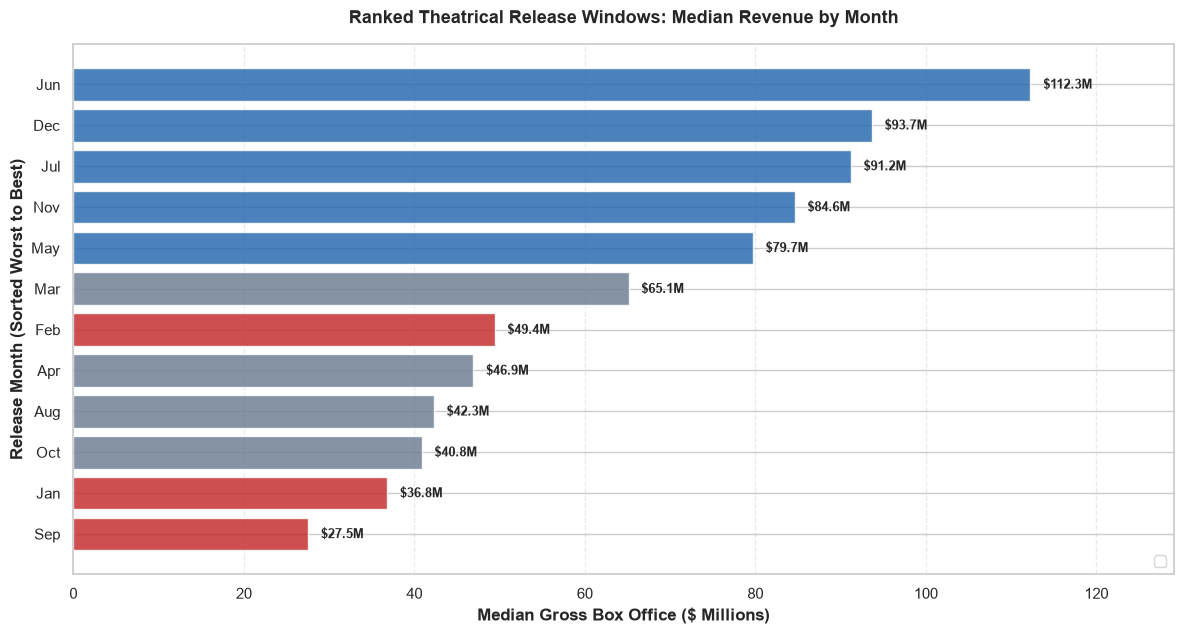

In [68]:
plt.figure(figsize=(12, 6.5))

# Sort values descending for chart representation
sorted_df = monthly_summary.sort_values(by='median_revenue', ascending=True).reset_index(drop=True)

# Highlight: Top 3 months green, Bottom 3 months red, Others gray
bar_colors = []
for m in sorted_df['release_month']:
    if m in ['Jun', 'May', 'Jul', 'Dec', 'Nov']:
        bar_colors.append('#2B6CB0')  # Prime theatrical windows
    elif m in ['Jan', 'Sep', 'Feb']:
        bar_colors.append('#C53030')  # Traditional dump months
    else:
        bar_colors.append('#718096')  # Mid-tier months

bars = plt.barh(
    sorted_df['release_month'], 
    sorted_df['median_revenue'] / 1e6, 
    color=bar_colors, 
    alpha=0.85
)


# Add revenue annotations on bars
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1.5, bar.get_y() + bar.get_height() / 2, f"${w:.1f}M", va='center', fontsize=9, weight='bold')

plt.title('Ranked Theatrical Release Windows: Median Revenue by Month', fontsize=13, weight='bold', pad=15)
plt.xlabel('Median Gross Box Office ($ Millions)', weight='bold')
plt.ylabel('Release Month (Sorted Worst to Best)', weight='bold')
plt.xlim(0, sorted_df['median_revenue'].max() / 1e6 * 1.15)
plt.grid(True, linestyle='--', alpha=0.4, axis='x')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

### Hypothesis 4 Conclusion: Supported (Theatrical Seasonality & The 4x Spread)

1. **The Peak Theatrical Windows (Summer & Holiday Season):**
   - **Absolute Dominance of June:** June registers as the single most lucrative calendar release window with a median gross box office of **$112.3M**, followed closely by December (**$93.7M**) and July (**$91.2M**).
   - **The Blockbuster Cluster:** The top 5 calendar months strictly encompass the Summer window (May–July) and the Holiday corridor (November–December). High school/college vacations and holiday consumer foot traffic create an environment capable of absorbing massive production budgets.

2. **Empirical Validation of "Dump Months" (The Autumn & Winter Lulls):**
   - **The September Trough:** September represents the absolute worst financial window for theatrical releases, recording a median revenue of just **$27.5M**—a **4.08x contraction** compared to June.
   - **The January Slump:** January confirms its reputation as the post-holiday write-off period with a median revenue of **$36.8M**. 
   - **February Nuance:** While historically classified among dump months, February outperforms January and September (**$49.4M**), frequently bolstered by targeted holiday marketing (Valentine's Day and Presidents' Day long weekends).

3. **Strategic Portfolio Implications:**
   - Release timing acts as a multiplier of market ceiling. Studios systematically route high-budget franchise assets into June/July and November/December to maximize throughput, while offloading high-risk or lower-appeal titles into September and January to mitigate marketing exposure.

**Verdict:** The release calendar is not arbitrary; theatrical performance exhibits extreme seasonality with an over 400% revenue disparity between peak and dump windows.